# Augmentation, distribution shift and calibration

Does translation augmentation help when digit placement changes?

I compare an unchanged training set with random shifts, then evaluate a fixed shifted test view. Temperature scaling is fitted on validation logits and checked on clean and shifted images.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import (
    Trainer,
    TrainConfig,
    classification_scores,
    digits_data,
    image_grid,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "05_augmentation_and_calibration"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Data and split

The 1,797 handwritten digit images come from `sklearn.datasets.load_digits`. Intensities are divided by the known sensor maximum of 16. The original 8 by 8 images are resized to 16 by 16 for the convolutional experiments. Resizing adds no measured detail. The split is stratified: 60% train, 20% validation and 20% test.

{'train': 1077, 'validation': 360, 'test': 360}


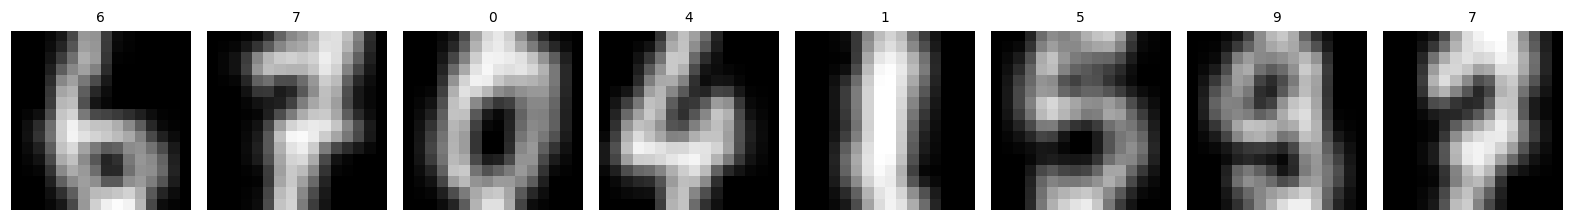

In [5]:
from vision_projects.models import LeNet

data = digits_data()
train_loader, validation_loader, test_loader = data.loaders()
train_images, train_labels = data.train.tensors
print(
    {
        "train": len(data.train),
        "validation": len(data.validation),
        "test": len(data.test),
    }
)
image_grid(train_images[:8], output / "examples.png", train_labels[:8].tolist())

## A translation transform

Zero-filled translations avoid wraparound, which would place removed pixels on the opposite border. Training shifts are random; validation stays clean. The test shift is fixed in advance at two pixels to the right.

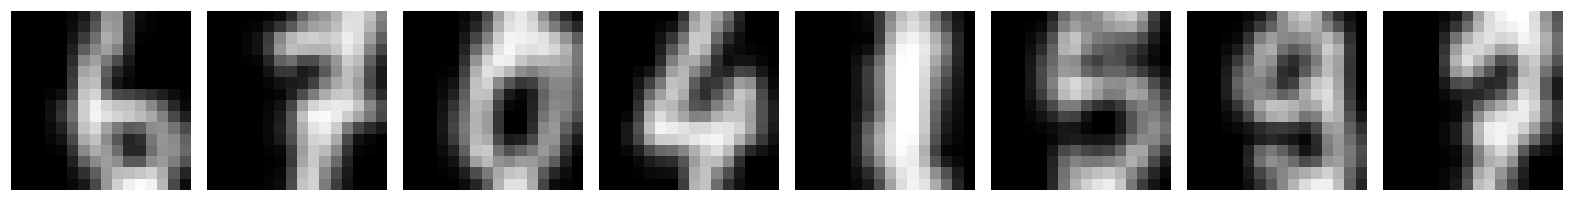

In [7]:
def translate(images, dx, dy):
    shifted = torch.roll(images, shifts=(dy, dx), dims=(-2, -1)).clone()
    if dx > 0:
        shifted[..., :dx] = 0
    if dx < 0:
        shifted[..., dx:] = 0
    if dy > 0:
        shifted[..., :dy, :] = 0
    if dy < 0:
        shifted[..., dy:, :] = 0
    return shifted


class ShiftedDigits(torch.utils.data.Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]
        dx, dy = torch.randint(-2, 3, (2,)).tolist()
        return translate(image, dx, dy), label


image_grid(translate(train_images[:8], 2, 0), output / "shifted.png")
assert torch.equal(translate(train_images[:2], 0, 0), train_images[:2])

## Matched training budgets

Both networks use the same epoch budget and parameterization. This is one specified augmentation comparison, not a search over test shifts. More epochs may change the relative outcomes.

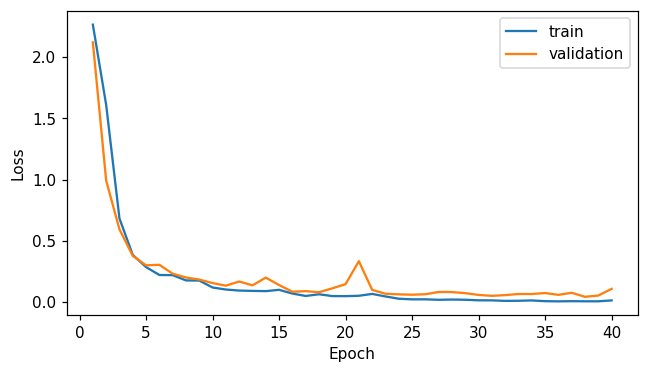

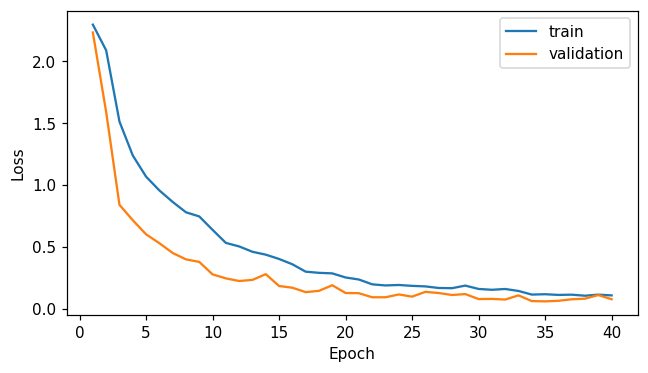

             model  accuracy  macro_f1       nll
0            plain  0.977778  0.977984  0.044613
1  shift_augmented  0.983333  0.983475  0.061988 selected: plain


In [9]:
models, validation_scores = {}, []
for name, dataset in [
    ("plain", data.train),
    ("shift_augmented", ShiftedDigits(data.train)),
]:
    seed_everything()
    model = LeNet()
    train_loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=True,
        generator=torch.Generator().manual_seed(1031),
    )
    history = Trainer(model, nn.CrossEntropyLoss(), TrainConfig(epochs=EPOCHS)).fit(
        train_loader, validation_loader
    )
    plot_history(history, output / f"{name}_loss.png")
    val_logits, val_labels = predict(model, validation_loader)
    validation_scores.append(
        {"model": name, **classification_scores(val_logits, val_labels)}
    )
    models[name] = model
selected = min(validation_scores, key=lambda row: row["nll"])["model"]
print(pd.DataFrame(validation_scores), "selected:", selected)

## Validation temperature

A temperature $T>0$ rescales logits as $z/T$. It changes confidence while preserving the predicted class. The scalar is selected by validation NLL over a fixed grid. Expected calibration error summarizes confidence bins but is sensitive to bin boundaries and sample count.

In [11]:
model = models[selected]
val_logits, val_labels = predict(model, validation_loader)
temperatures = torch.linspace(0.5, 3, 51)
losses = torch.tensor(
    [
        F.cross_entropy(val_logits / temperature, val_labels).item()
        for temperature in temperatures
    ]
)
temperature = float(temperatures[losses.argmin()])


def calibration(logits, labels):
    confidence, prediction = logits.softmax(-1).max(-1)
    correct = prediction.eq(labels).float()
    rows, ece = [], 0.0
    for lower in np.linspace(0, 0.9, 10):
        selected_bin = (confidence > lower) & (confidence <= lower + 0.1 + 1e-7)
        if selected_bin.any():
            accuracy = correct[selected_bin].mean().item()
            mean_confidence = confidence[selected_bin].mean().item()
            ece += selected_bin.float().mean().item() * abs(accuracy - mean_confidence)
            rows.append((mean_confidence, accuracy, int(selected_bin.sum())))
    return ece, rows


print({"temperature": temperature, "validation_nll": float(losses.min())})

{'temperature': 0.8999999761581421, 'validation_nll': 0.04438171163201332}


## Clean and shifted evaluation

Calibration learned on clean validation images can fail after a distribution shift. The diagram reports occupied confidence bins and keeps the diagonal as a visual reference. Each model is also evaluated before calibration.

             model     view  accuracy  macro_f1       nll
0            plain    clean  0.975000  0.974789  0.103380
1            plain  shifted  0.625000  0.611989  2.685867
2  shift_augmented    clean  0.975000  0.974690  0.082931
3  shift_augmented  shifted  0.952778  0.952561  0.152839


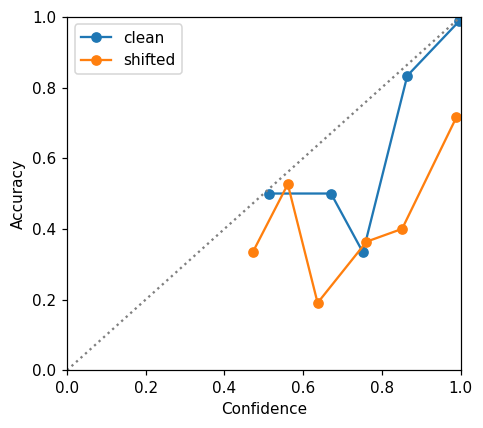

In [13]:
shifted_test = DataLoader(
    TensorDataset(translate(data.test.tensors[0], 2, 0), data.test.tensors[1]),
    batch_size=64,
)
comparisons = []
for name, candidate in models.items():
    for view, loader in [("clean", test_loader), ("shifted", shifted_test)]:
        logits, labels = predict(candidate, loader)
        comparisons.append(
            {"model": name, "view": view, **classification_scores(logits, labels)}
        )
print(pd.DataFrame(comparisons))
fig, axis = plt.subplots(figsize=(4.5, 4))
calibration_rows = []
for view, loader in [("clean", test_loader), ("shifted", shifted_test)]:
    logits, labels = predict(model, loader)
    ece, bins = calibration(logits / temperature, labels)
    axis.plot([row[0] for row in bins], [row[1] for row in bins], "o-", label=view)
    calibration_rows.append(
        {
            "view": view,
            "ece": ece,
            **classification_scores(logits / temperature, labels),
        }
    )
axis.plot([0, 1], [0, 1], color="gray", linestyle=":")
axis.set(xlabel="Confidence", ylabel="Accuracy", xlim=(0, 1), ylim=(0, 1))
axis.legend()
fig.tight_layout()
fig.savefig(output / "calibration.png", dpi=140)
plt.show()
results = {
    "validation": validation_scores,
    "test_comparison": comparisons,
    "temperature": temperature,
    "calibrated": calibration_rows,
}

## Reading the result

The clean and shifted views reuse the same test labels, so their difference is paired. Temperature scaling can reduce NLL without improving accuracy. ECE is a descriptive statistic for these bins, not a guarantee about individual predictions.

In [15]:
result_path = root / "results" / "05_augmentation_and_calibration.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/05_augmentation_and_calibration.json


## Next experiment

Compare small rotations with translations using predefined perturbation levels. Fit calibration on a separate shifted validation view if deployment images are known to be displaced.

## Sources

UniPd Computer Vision and Cognitive Systems: uploaded filtering, SIFT, BoW, MLP and CNN notebooks. [HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.